# Problem

Recover the effective isotropic microfacet slope density of **measured gold metallic paint**. The observation is the full MERL RGB angular table; the selected published inverse uses its coincident illumination/view slice. Recover all 90 density samples and both roughness moments. There is **no independent microscopic ground truth**. Original C++ results below are method references, not true surface measurements.

The material can contain scattering beyond the assumed single-scattering microfacet mechanism. We therefore do not infer composition, claim an exact surface topography, or claim an angle-dependent Fresnel/complete BRDF reconstruction.

In [1]:
from pathlib import Path
import sys,time,json,subprocess
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,RGB_SCALE,LUMINANCE
from src.solvers import reconstruct
from src.physics_model import mass,roughness,eigen_residual,parametric_pdf
from src.visualization import comparison_metrics
plt.rcParams.update({'figure.figsize':(11,4),'font.size':10,'axes.grid':True,'grid.alpha':.2})
data=load_data(ROOT/'data/raw_data.npz')
with np.load(ROOT/'notebooks/reference_outputs/upstream.npz') as f: native={k:f[k] for k in f.files}
print('Full measured table:',data.shape,'; native reference is not ground truth')

Full measured table: (3, 90, 90, 180) ; native reference is not ground truth


# Data

The MERL acquisition used a stationary calibrated camera, spherical sample and moving xenon light. HDR exposures were calibrated and averaged into an isotropic half/difference-angle table. These are real processed camera observations, not simulated reflectance. We preserve every encoded bin, including invalid negative values, and apply the published RGB conversion only during lookup. The plots show angular context beyond the restricted slice used for inversion.

The half-angle axis is nonuniform: its representative coordinate is $(j/90)^2\pi/2$. Difference polar and azimuth axes are uniform. The camera calibration is already incorporated in the released reflectance; no target-derived calibration is introduced.

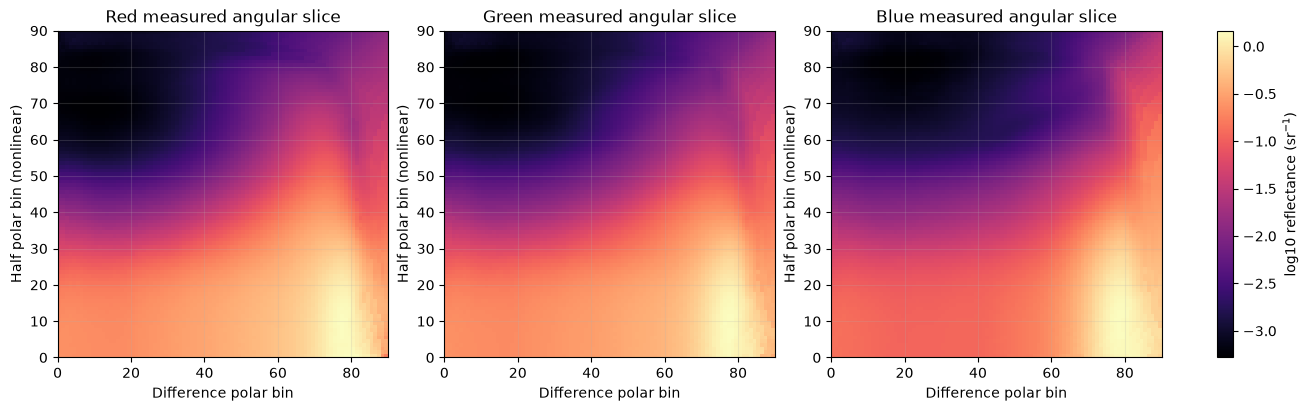

Invalid encoded entries: 917478


In [2]:
fig,ax=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for channel,a in enumerate(ax):
    z=data[channel,:,:,90]*RGB_SCALE[channel]
    im=a.imshow(np.log10(np.maximum(z,1e-5)),origin='lower',aspect='auto',extent=[0,90,0,90],cmap='magma')
    a.set(title=['Red','Green','Blue'][channel]+' measured angular slice',xlabel='Difference polar bin',ylabel='Half polar bin (nonlinear)')
fig.colorbar(im,ax=ax,label='log10 reflectance (sr$^{-1}$)')
plt.show()
print('Invalid encoded entries:',int(np.sum(data<0)))

# Physics

Let $s=\tan\theta$ be the slope magnitude and $P(s)$ the isotropic **two-dimensional** slope density. The radial probability is $2\pi sP(s)ds$, not $P(s)ds$. The orientation distribution is $D(\theta)=P(\tan\theta)/\cos^4\theta$.

$$2\pi\int_0^\infty P(s)s\,ds=1,\qquad f(\theta,\theta)=\frac{F_0D(\theta)G_1(\theta)}{4\cos^2\theta}.$$

Here $f$ is measured luminance reflectance, $G_1$ the Smith monostatic visibility, and $F_0$ a constant normal-incidence Fresnel scale because the difference angle is zero. Define the azimuth factor

$$A(\theta,\eta)=\int_0^{2\pi}\max(1,\tan\theta\tan\eta\cos\phi)\,d\phi.$$

With $u=\tan\eta$, visibility is $G_1(\theta)=1/[\int P(u)uA(\theta,\arctan u)du]$. Combining these expressions gives a positive integral eigenproblem for $P$. This assumes isotropy and single-scattering Smith visibility with no fitted diffuse component. Reflectance outside the selected coincident-direction slice can violate this model.

# Method

Use $t_i=i\sqrt{\pi/2}/89$, $\theta_i=t_i^2$, and $s_i=\tan\theta_i$, for $i=0,\ldots,88$. With $f_i$ the observed luminance and $\Delta t=\sqrt{\pi/2}/89$, the discrete operator is

$$K_{ij}=8\Delta t f_i\cos^6\theta_i\, t_j s_j\cos^{-2}\theta_j\, A(\theta_i,\theta_j),\qquad F_0p=Kp.$$

Start with ones and execute four power updates, append the zero horizon endpoint, and normalize using the original 128-point left quadrature in square-root angle. The original azimuth floating loop contains 361 samples; this numerical convention is retained. Linear interpolation is in $x=\sqrt{2\arctan(s)/\pi}$. The roughness parameters are $\alpha_B=\sqrt{2E[s_x^2]}$ and $\alpha_G=E[|s_x|]$, evaluated using the same quadrature. The former yields a Beckmann approximation, the latter a GGX approximation. Their shapes need not match the full density.

The original vector allocation was corrected from reserve to resize after a checked C++ run failed. The corrected and unchecked original results were bit-identical. A separate error in the unused Fresnel direction conversion is documented and excluded from this task's claims.

In [3]:
start=time.perf_counter()
result,diag=reconstruct(data)
elapsed=time.perf_counter()-start
pdf=result['reconstruction'][0]; alpha=result['roughness'][0]
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',**result)
proc=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
assert proc.returncode==0,proc.stderr
report=json.loads((ROOT/'output/judge_report.json').read_text())
print('Fresh full reconstruction seconds:',elapsed)
print('Beckmann, GGX alpha:',alpha)
print(json.dumps(report['metrics'],indent=2))

Fresh full reconstruction seconds: 0.002129899978172034
Beckmann, GGX alpha: [0.42808656 0.18221309]
{
  "ncc": 0.9999999999999998,
  "nrmse": 1.50037364355385e-16,
  "roughness_error": 3.885780586188048e-16,
  "mass_error": 2.220446049250313e-16,
  "moment_error": 1.1102230246251565e-16,
  "eigen_residual": 4.664496566781733e-08
}


# Results

First compare measured backscatter channels with the positive operator that couples their inferred slopes. Then compare the freshly reconstructed full density and both roughness moments with the independently executed original method. These are numerical reproduction tests, not physical accuracy scores.

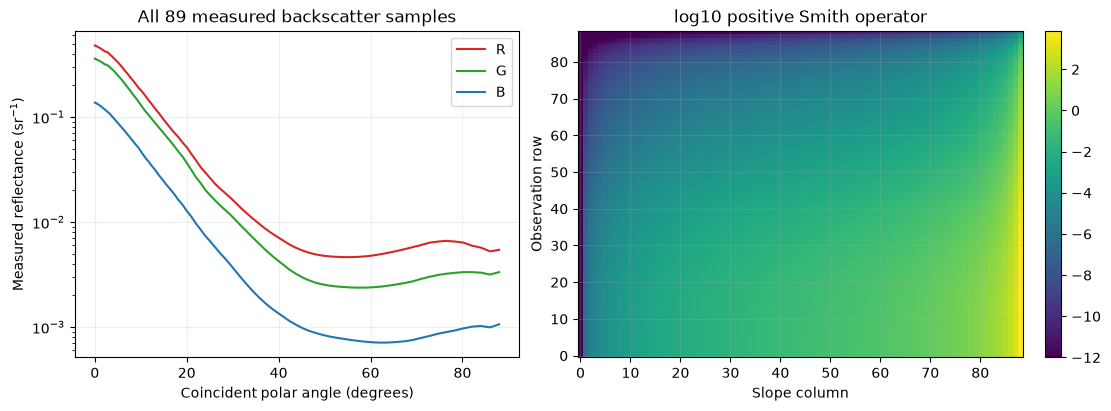

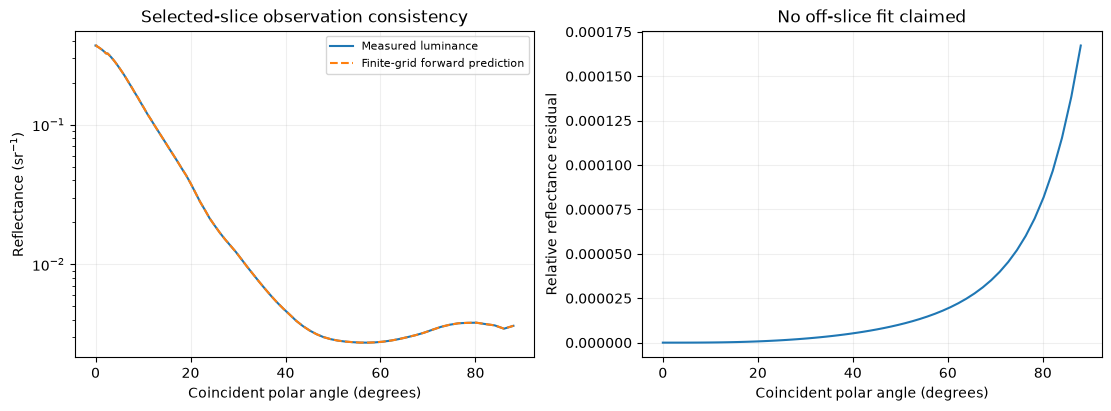

Effective scalar eigenvalue: 0.19943038996594062 maximum relative backscatter residual: 0.00016726222007408458


In [4]:
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for j,color in enumerate(['tab:red','tab:green','tab:blue']): ax[0].semilogy(np.rad2deg(diag['theta']),diag['rgb'][:,j],color=color,label=['R','G','B'][j])
ax[0].set(xlabel='Coincident polar angle (degrees)',ylabel='Measured reflectance (sr$^{-1}$)',title='All 89 measured backscatter samples'); ax[0].legend()
im=ax[1].imshow(np.log10(np.maximum(diag['kernel'],1e-12)),origin='lower',aspect='auto',cmap='viridis')
ax[1].set(xlabel='Slope column',ylabel='Observation row',title='log10 positive Smith operator'); fig.colorbar(im,ax=ax[1])
plt.show()
lum=diag['rgb']@LUMINANCE
relative,effective_scale=eigen_residual(diag['kernel'],pdf)
predicted=effective_scale*pdf[:89]/((diag['kernel']/lum[:,None])@pdf[:89])
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
ax[0].semilogy(np.rad2deg(diag['theta']),lum,label='Measured luminance')
ax[0].semilogy(np.rad2deg(diag['theta']),predicted,'--',label='Finite-grid forward prediction')
ax[0].set(xlabel='Coincident polar angle (degrees)',ylabel='Reflectance (sr$^{-1}$)',title='Selected-slice observation consistency'); ax[0].legend(fontsize=8)
ax[1].plot(np.rad2deg(diag['theta']),(predicted-lum)/lum)
ax[1].set(xlabel='Coincident polar angle (degrees)',ylabel='Relative reflectance residual',title='No off-slice fit claimed')
plt.show()
print('Effective scalar eigenvalue:',effective_scale,'maximum relative backscatter residual:',np.max(abs(predicted-lum)/lum))


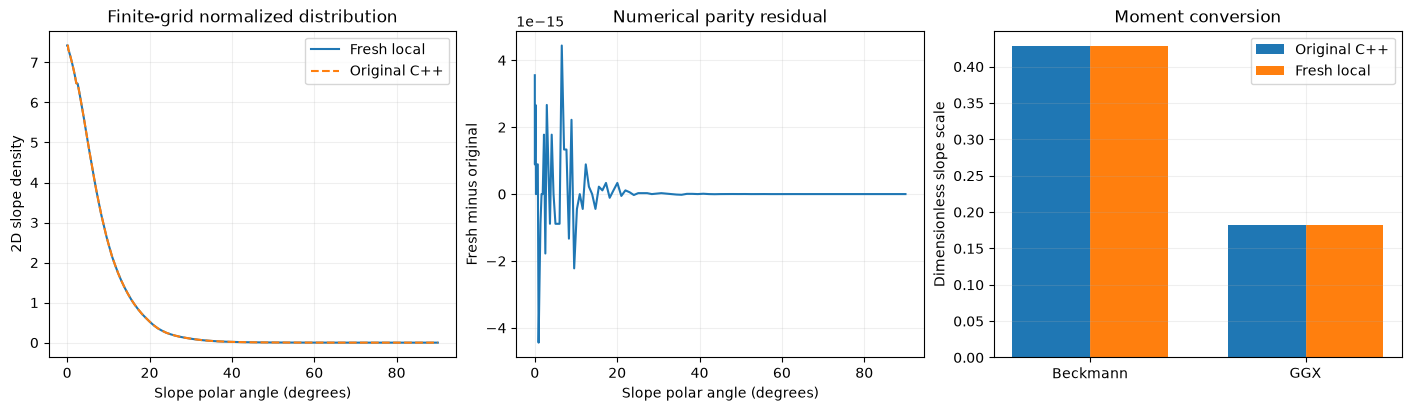

In [5]:
angle=(np.arange(90)/89)**2*90
fig,ax=plt.subplots(1,3,figsize=(14,4),layout='constrained')
ax[0].plot(angle,pdf,label='Fresh local'); ax[0].plot(angle,native['reconstruction'][0],'--',label='Original C++'); ax[0].set(xlabel='Slope polar angle (degrees)',ylabel='2D slope density',title='Finite-grid normalized distribution'); ax[0].legend()
ax[1].plot(angle,pdf-native['reconstruction'][0]); ax[1].set(xlabel='Slope polar angle (degrees)',ylabel='Fresh minus original',title='Numerical parity residual')
x=np.arange(2); ax[2].bar(x-.18,native['roughness'][0],.36,label='Original C++'); ax[2].bar(x+.18,alpha,.36,label='Fresh local'); ax[2].set(xticks=x,xticklabels=['Beckmann','GGX'],ylabel='Dimensionless slope scale',title='Moment conversion'); ax[2].legend()
plt.show()

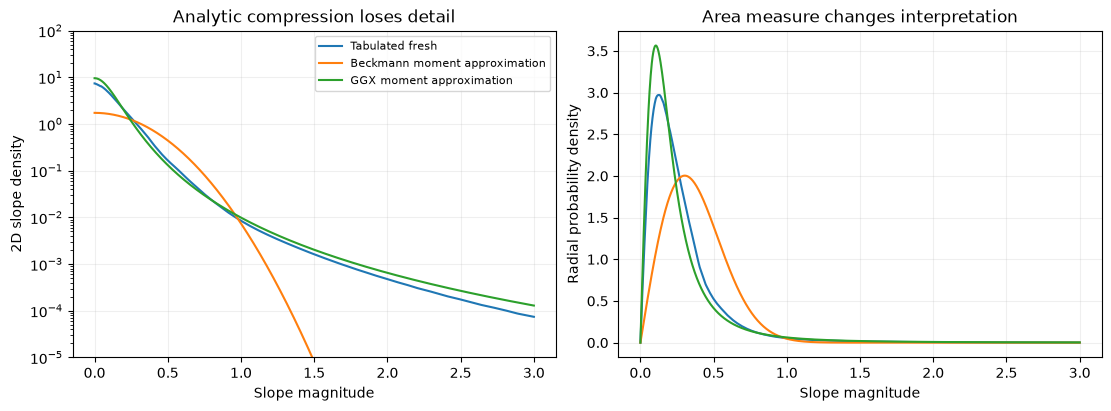

In [6]:
s=np.linspace(0,3,1200)
tab=np.interp(np.sqrt(2*np.arctan(s)/np.pi),np.arange(90)/89,pdf)
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
curves={'Tabulated fresh':tab,'Beckmann moment approximation':parametric_pdf(s,alpha[0],'beckmann'),'GGX moment approximation':parametric_pdf(s,alpha[1],'ggx')}
for label,y in curves.items():
    ax[0].semilogy(s,np.maximum(y,1e-12),label=label); ax[1].plot(s,2*np.pi*s*y,label=label)
ax[0].set(xlabel='Slope magnitude',ylabel='2D slope density',ylim=(1e-5,100),title='Analytic compression loses detail'); ax[0].legend(fontsize=8)
ax[1].set(xlabel='Slope magnitude',ylabel='Radial probability density',title='Area measure changes interpretation')
plt.show()

The following comparisons actively rerun the selected inverse with different power counts. The direct eigenvector is an independent linear-algebra diagnostic. It is not substituted for the prescribed four-step output. The continuous integral uses a different quadrature and is reported separately from the exact normalization contract.

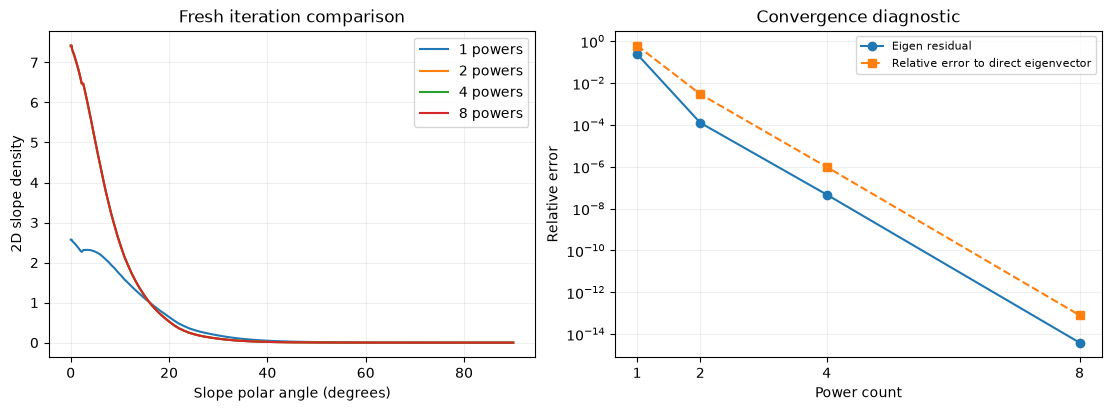

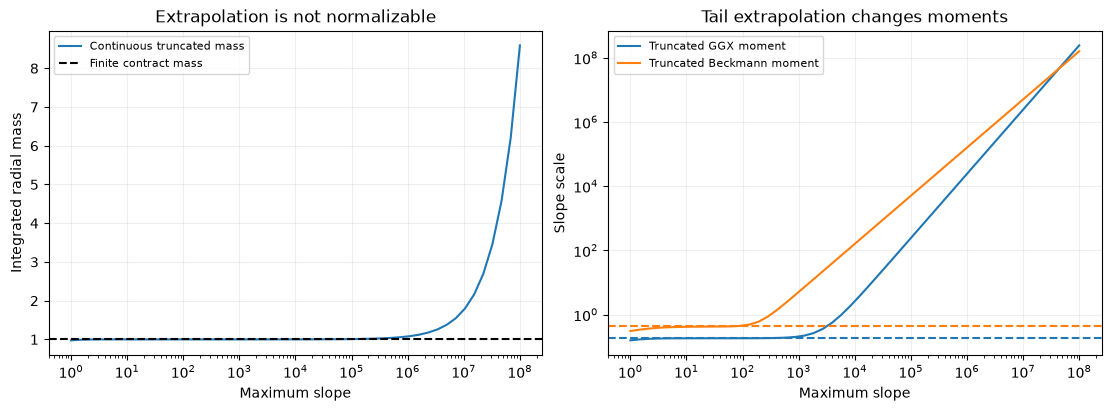

Continuous mass at slope 1e8: 8.590516764468454
Finite contract mass: 1.0 maximum integration slope: 40.89529491397538


In [7]:
from scipy.integrate import quad
comparisons={n:reconstruct(data,iterations=n) for n in [1,2,4,8]}
values,vectors=np.linalg.eig(diag['kernel']); direct=np.r_[vectors[:,np.argmax(values.real)].real,0.]; direct/=mass(direct)
counts=list(comparisons)
residuals=[eigen_residual(d['kernel'],r['reconstruction'][0])[0] for r,d in comparisons.values()]
errors=[np.linalg.norm(r['reconstruction'][0]-direct)/np.linalg.norm(direct) for r,d in comparisons.values()]
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for n,(r,d) in comparisons.items(): ax[0].plot(angle,r['reconstruction'][0],label=str(n)+' powers')
ax[0].set(xlabel='Slope polar angle (degrees)',ylabel='2D slope density',title='Fresh iteration comparison'); ax[0].legend()
ax[1].semilogy(counts,residuals,'o-',label='Eigen residual'); ax[1].semilogy(counts,errors,'s--',label='Relative error to direct eigenvector'); ax[1].set(xlabel='Power count',ylabel='Relative error',title='Convergence diagnostic',xticks=counts); ax[1].legend(fontsize=8)
plt.show()
# Independent continuous integration in log-slope avoids unresolved endpoint singularities.
def continuous_moment(cut,power=0):
    def g(logs):
        s=np.exp(logs); x=np.sqrt(2*np.arctan(s)/np.pi)
        return 2*np.pi*np.interp(x,np.arange(90)/89,pdf)*s**(2+power)
    stop=np.log(cut)
    knots=np.log(np.tan((np.arange(1,89)/89)**2*np.pi/2))
    breaks=np.r_[-25,knots[(knots>-25)&(knots<stop)],stop]
    return sum(quad(g,a,b,epsabs=1e-9)[0] for a,b in zip(breaks[:-1],breaks[1:]))
limits=np.logspace(0,8,50)
cm=np.array([continuous_moment(x) for x in limits])
first=np.array([continuous_moment(x,1)*2/np.pi for x in limits])
second=np.sqrt(np.array([continuous_moment(x,2) for x in limits]))
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
ax[0].semilogx(limits,cm,label='Continuous truncated mass'); ax[0].axhline(1,color='k',ls='--',label='Finite contract mass')
ax[0].set(xlabel='Maximum slope',ylabel='Integrated radial mass',title='Extrapolation is not normalizable'); ax[0].legend(fontsize=8)
ax[1].loglog(limits,first,label='Truncated GGX moment'); ax[1].loglog(limits,second,label='Truncated Beckmann moment')
ax[1].axhline(alpha[0],color='C1',ls='--'); ax[1].axhline(alpha[1],color='C0',ls='--')
ax[1].set(xlabel='Maximum slope',ylabel='Slope scale',title='Tail extrapolation changes moments'); ax[1].legend(fontsize=8)
plt.show()
print('Continuous mass at slope 1e8:',cm[-1])
print('Finite contract mass:',mass(pdf),'maximum integration slope:',np.tan((127/128)**2*np.pi/2))


A final sensitivity check scales measured intensities and perturbs the selected measured RGB values by a fixed 1% sinusoidal modulation. The modulation is explicitly synthetic and supplementary; the benchmark input remains the original measurement. This tests scale cancellation and sensitivity to angular calibration error without presenting perturbed observations as another acquisition.

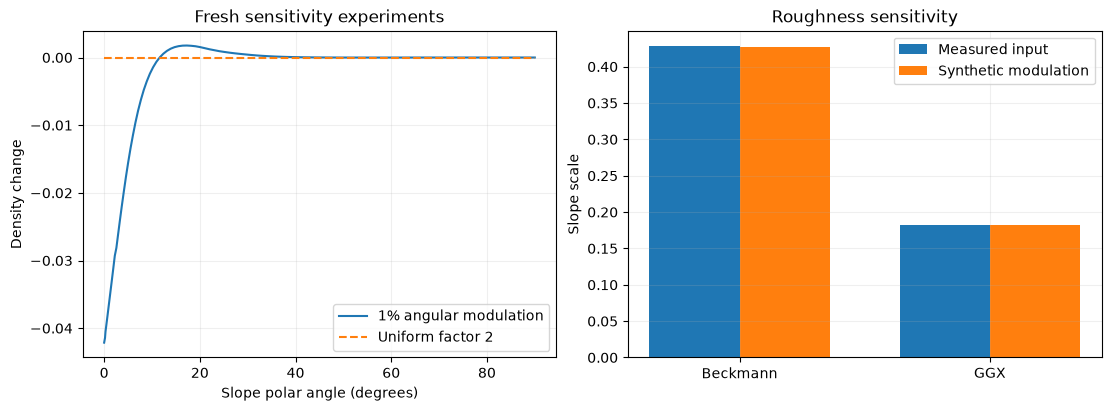

Uniform scale max PDF change: 0.0


In [8]:
from src.physics_model import build_kernel
scaled,_=reconstruct(data*2)
lum=diag['rgb']@LUMINANCE
perturbed=lum*(1+.01*np.sin(3*diag['theta']))
k=build_kernel(diag['theta'],perturbed); v=np.ones(89)
for _ in range(4): v=k@v
pp=np.r_[v,0.]; pp/=mass(pp)
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
ax[0].plot(angle,pp-pdf,label='1% angular modulation'); ax[0].plot(angle,scaled['reconstruction'][0]-pdf,'--',label='Uniform factor 2'); ax[0].set(xlabel='Slope polar angle (degrees)',ylabel='Density change',title='Fresh sensitivity experiments'); ax[0].legend()
ax[1].bar(np.arange(2)-.18,alpha,.36,label='Measured input'); ax[1].bar(np.arange(2)+.18,roughness(pp),.36,label='Synthetic modulation'); ax[1].set(xticks=[0,1],xticklabels=['Beckmann','GGX'],ylabel='Slope scale',title='Roughness sensitivity'); ax[1].legend()
plt.show()
print('Uniform scale max PDF change:',np.max(abs(scaled['reconstruction'][0]-pdf)))

# Conclusion

The complete measured-data path reproduces the original 90-sample slope distribution and both moment-based roughness parameters, passes the standalone numerical and physical criteria, and exhibits rapid positive-operator convergence. Analytic Beckmann/GGX summaries discard features of the tabulated profile.

The distribution is normalized under the published finite quadrature convention. Its linear interpolation near an infinite-slope endpoint is not a guaranteed continuous probability model at arbitrarily grazing angles; truncated continuous mass diagnostics expose this limitation. The effective optical distribution is not microscopy truth. Results apply to the selected isotropic backscatter model, not complete Fresnel recovery or every RGB angular measurement. Source bugs and the allocation-only correction are recorded in validation evidence.